In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn wordcloud spacy

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")

df = pd.read_csv("mtsamples.csv")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (4999, 6)

Columns: ['unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'transcription', 'keywords']


,unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."



Missing values:
unnamed: 0              0
description             0
medical_specialty       0
sample_name             0
transcription          33
keywords             1068
dtype: int64


Dataset loaded successfully!
Original dataset shape: (4999, 6)
Columns: ['Unnamed: 0', 'description', 'medical_specialty', 'sample_name', 'transcription', 'keywords']

Cleaned dataset shape: (4966, 2)
Number of specialties: 40

Top 10 medical specialties:
medical_specialty
Surgery                          1088
Consult - History and Phy.        516
Cardiovascular / Pulmonary        371
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  224
Neurology                         223
SOAP / Chart / Progress Notes     166
Urology                           156
Name: count, dtype: int64

========== MODEL RESULTS ==========
Accuracy: 0.0986
Accuracy percentage: 9.86%

Classification Report:
                               precision    recall  f1-score   support

         Allergy / Immunology       0.00      0.00      0.00         1
                      Autopsy       1.00      1.00      1.00         2
 

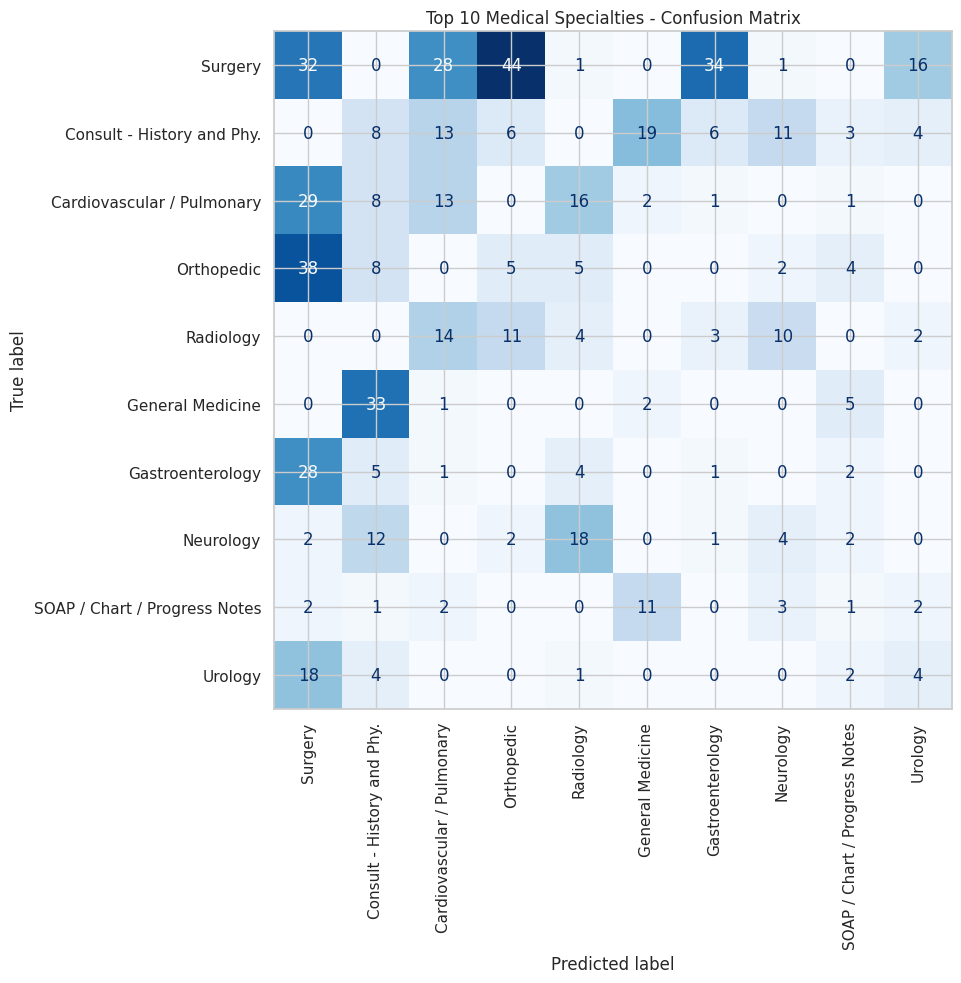


Predicted specialty for sample text:
Cardiovascular / Pulmonary

Model saved to /content/medical_specialty_model.pkl

T7 clinical-text classification completed successfully.


In [22]:

# ============================================================
# T7: Healthcare Analytics - Medical Specialty Classification
# Dataset: MTSamples Medical Transcriptions
# ============================================================

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

# 1. Load dataset
FILE_PATH = "/content/mtsamples.csv"

if not os.path.exists(FILE_PATH):
    # Try the current working directory
    FILE_PATH = "mtsamples.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        "mtsamples.csv was not found. Upload it to Colab "
        "or place it in the current working directory."
    )

df = pd.read_csv(FILE_PATH)

print("Dataset loaded successfully!")
print("Original dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# 2. Check required columns
required_columns = ["transcription", "medical_specialty"]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        "Check the column names in your CSV."
    )

# 3. Clean data
df = df[required_columns].copy()

df["transcription"] = (
    df["transcription"]
    .fillna("")
    .astype(str)
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df["medical_specialty"] = (
    df["medical_specialty"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Remove empty records
df = df[
    (df["transcription"] != "") &
    (df["medical_specialty"] != "")
].copy()

# Remove specialties with fewer than 2 records
specialty_counts = df["medical_specialty"].value_counts()
valid_specialties = specialty_counts[
    specialty_counts >= 2
].index

df = df[
    df["medical_specialty"].isin(valid_specialties)
].copy()

if df["medical_specialty"].nunique() < 2:
    raise ValueError(
        "At least two specialties with sufficient records are required."
    )

print("\nCleaned dataset shape:", df.shape)
print("Number of specialties:", df["medical_specialty"].nunique())

# 4. Display top specialties
print("\nTop 10 medical specialties:")
print(df["medical_specialty"].value_counts().head(10))

# 5. Prepare features and target
X = df["transcription"]
y = df["medical_specialty"]

# Stratify only if every class has enough records for the split
stratify_target = y if y.value_counts().min() >= 2 else None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)

# 6. Build and train model
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            stop_words="english",
            ngram_range=(1, 2),
            min_df=1
        )
    ),
    ("classifier", LinearSVC())
])

model.fit(X_train, y_train)

# 7. Predict
y_pred = model.predict(X_test)

# 8. Evaluate model
accuracy = accuracy_score(y_test, y_pred)

print("\n========== MODEL RESULTS ==========")
print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# 9. Plot confusion matrix for the 10 most frequent specialties
top_classes = (
    df["medical_specialty"]
    .value_counts()
    .head(10)
    .index
    .tolist()
)

# Keep only test records belonging to these specialties
mask = y_test.isin(top_classes)

if mask.sum() > 0:
    fig, ax = plt.subplots(figsize=(12, 10))

    ConfusionMatrixDisplay.from_predictions(
        y_test[mask],
        y_pred[mask],
        labels=top_classes,
        xticks_rotation=90,
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title("Top 10 Medical Specialties - Confusion Matrix")
    plt.tight_layout()
    plt.show()
else:
    print("No test records available for the top 10 specialties.")

# 10. Predict specialty for a new transcription
new_transcription = """
Patient presents with chest pain and shortness of breath.
The patient has a history of hypertension.
Physical examination and diagnostic evaluation were performed.
"""

predicted_specialty = model.predict([new_transcription])[0]

print("\nPredicted specialty for sample text:")
print(predicted_specialty)

# 11. Save the trained model
import joblib

joblib.dump(model, "/content/medical_specialty_model.pkl")
print("\nModel saved to /content/medical_specialty_model.pkl")

print("\nT7 clinical-text classification completed successfully.")


In [3]:
# Adjust automatically if the dataset uses the standard MTSamples columns
text_col = "transcription"
specialty_col = "medical_specialty"

if text_col not in df.columns:
    raise ValueError(f"Text column not found. Available columns: {df.columns.tolist()}")

df[text_col] = df[text_col].fillna("").astype(str)

if specialty_col in df.columns:
    df[specialty_col] = (
        df[specialty_col].fillna("Unknown").astype(str).str.strip()
    )

# Remove empty transcription records
df = df[df[text_col].str.strip().ne("")].copy()

# Add cleaned text for NLP
df["clean_text"] = (
    df[text_col]
    .str.lower()
    .str.replace(r"[^a-z\s]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df["word_count"] = df[text_col].str.split().str.len()

print("Usable records:", len(df))
display(df[[text_col, "clean_text", "word_count"]].head())

Usable records: 4966


,transcription,clean_text,word_count
0,"SUBJECTIVE:, This 23-year-old white female pr...",subjective this year old white female presents...,204
1,"PAST MEDICAL HISTORY:, He has difficulty climb...",past medical history he has difficulty climbin...,350
2,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...",history of present illness i have seen abc tod...,716
3,"2-D M-MODE: , ,1. Left atrial enlargement wit...",d m mode left atrial enlargement with left atr...,68
4,1. The left ventricular cavity size and wall ...,the left ventricular cavity size and wall thic...,229


Healthcare Planning Indicators — Top 10 Specialties


,medical_specialty,report_count,average_words,unique_reports,share_percent
38,Surgery,1088,484.15,1088,21.91
5,Consult - History and Phy.,516,558.06,516,10.39
3,Cardiovascular / Pulmonary,371,433.60,371,7.47
27,Orthopedic,355,559.12,355,7.15
33,Radiology,273,274.61,273,5.50
15,General Medicine,259,467.10,259,5.22
14,Gastroenterology,224,358.69,224,4.51
22,Neurology,223,496.31,223,4.49
35,SOAP / Chart / Progress Notes,166,358.78,166,3.34
39,Urology,156,406.53,156,3.14


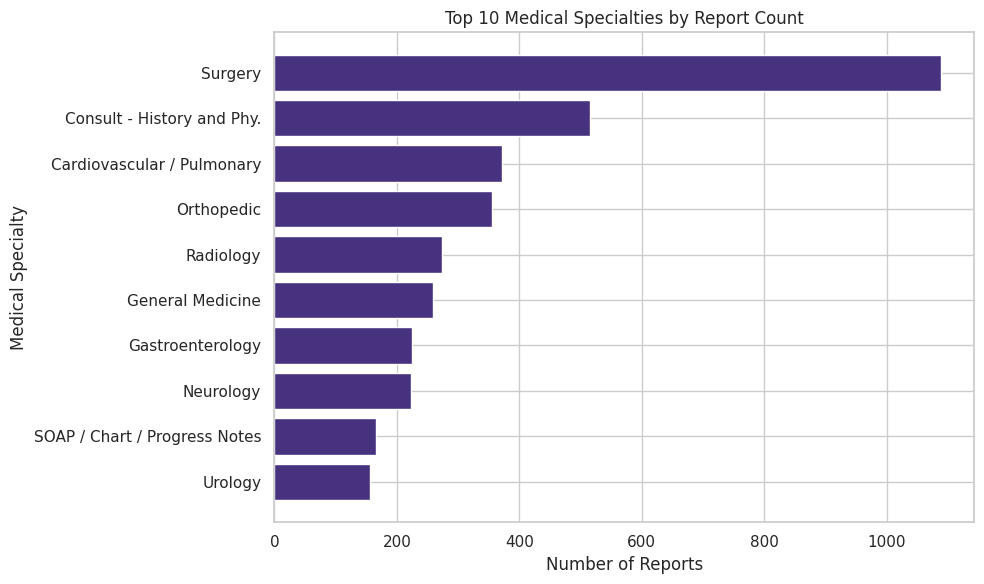

Saved: healthcare_planning_indicators.csv


In [24]:
# T8: Healthcare Planning Indicators

import pandas as pd
import matplotlib.pyplot as plt

# Ensure required columns exist
text_col = "transcription"
specialty_col = "medical_specialty"

if text_col not in df.columns or specialty_col not in df.columns:
    raise ValueError(
        f"Required columns not found. Available columns: {df.columns.tolist()}"
    )

# Create word_count if missing
if "word_count" not in df.columns:
    df["word_count"] = (
        df[text_col]
        .fillna("")
        .astype(str)
        .str.split()
        .str.len()
    )

# Clean missing values
df[specialty_col] = df[specialty_col].fillna("Unknown")
df["word_count"] = pd.to_numeric(
    df["word_count"], errors="coerce"
).fillna(0)

# Generate healthcare planning indicators
planning = df.groupby(specialty_col).agg(
    report_count=(text_col, "size"),
    average_words=("word_count", "mean"),
    unique_reports=(text_col, "nunique")
).reset_index()

planning["share_percent"] = (
    planning["report_count"] / len(df) * 100
).round(2)

planning["average_words"] = planning["average_words"].round(2)

# Display top 10 specialties
planning = planning.sort_values(
    "report_count", ascending=False
)

print("Healthcare Planning Indicators — Top 10 Specialties")
display(planning.head(10))

# Plot report counts
top10 = planning.head(10).sort_values("report_count")

plt.figure(figsize=(10, 6))
plt.barh(top10[specialty_col], top10["report_count"])
plt.xlabel("Number of Reports")
plt.ylabel("Medical Specialty")
plt.title("Top 10 Medical Specialties by Report Count")
plt.tight_layout()
plt.show()

# Save the planning indicators
planning.to_csv(
    "healthcare_planning_indicators.csv",
    index=False
)

print("Saved: healthcare_planning_indicators.csv")

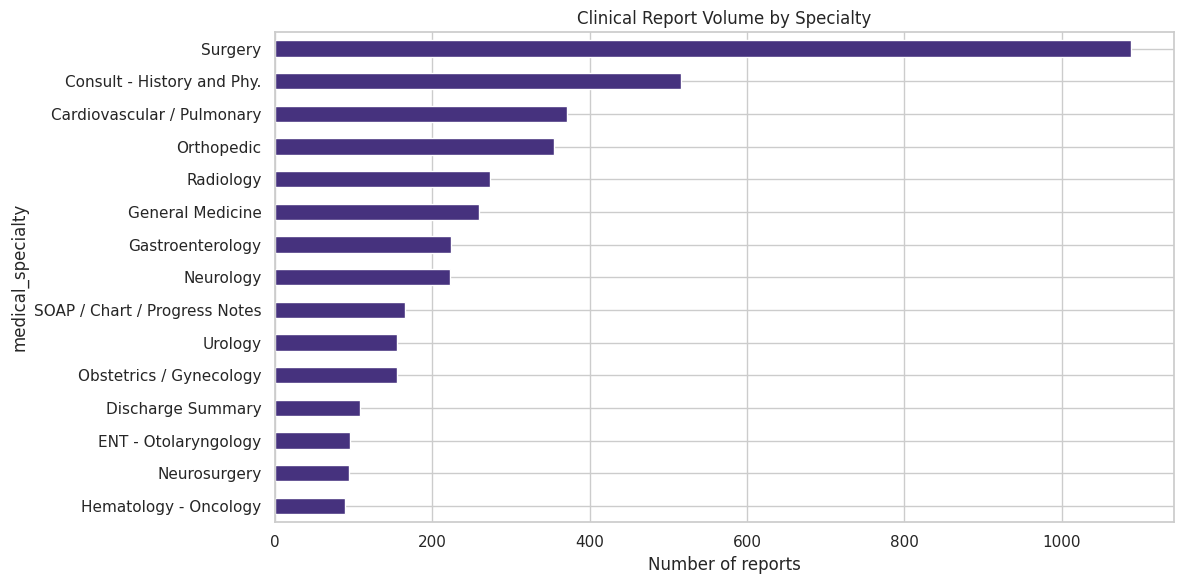

Accuracy: 0.15
                               precision    recall  f1-score   support

         Allergy / Immunology       0.17      1.00      0.29         1
                      Autopsy       1.00      1.00      1.00         2
                   Bariatrics       0.33      0.25      0.29         4
   Cardiovascular / Pulmonary       0.20      0.23      0.22        74
                 Chiropractic       0.00      0.00      0.00         3
   Consult - History and Phy.       0.01      0.01      0.01       103
   Cosmetic / Plastic Surgery       0.25      0.40      0.31         5
                    Dentistry       0.38      0.60      0.46         5
                  Dermatology       0.00      0.00      0.00         6
         Diets and Nutritions       0.00      0.00      0.00         2
            Discharge Summary       0.20      0.14      0.16        22
         ENT - Otolaryngology       0.27      0.32      0.29        19
       Emergency Room Reports       0.07      0.13      0.09 

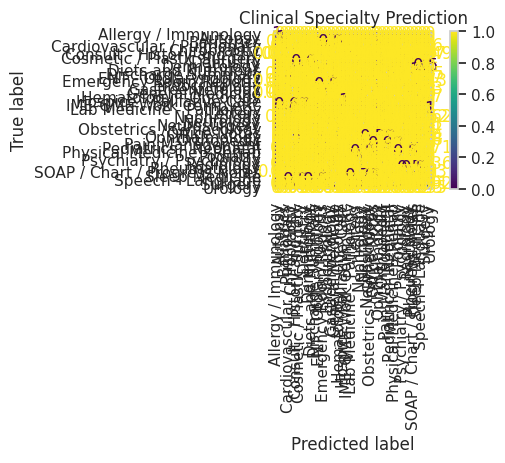

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# Analyze report volume by specialty
workload = df[specialty_col].value_counts().head(15)

plt.figure(figsize=(12, 6))
workload.sort_values().plot(kind="barh")
plt.title("Clinical Report Volume by Specialty")
plt.xlabel("Number of reports")
plt.tight_layout()
plt.show()

# Predict specialty from clinical transcription
model_df = df[
    df[specialty_col].notna()
    & (df[specialty_col] != "Unknown")
].copy()

# Keep classes with at least 5 examples
counts = model_df[specialty_col].value_counts()
model_df = model_df[
    model_df[specialty_col].isin(counts[counts >= 5].index)
]

X_train, X_test, y_train, y_test = train_test_split(
    model_df[text_col],
    model_df[specialty_col],
    test_size=0.2,
    random_state=42,
    stratify=model_df[specialty_col]
)

staffing_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000, stop_words="english", ngram_range=(1, 2)
    )),
    ("classifier", LinearSVC(class_weight="balanced"))
])

staffing_model.fit(X_train, y_train)
pred = staffing_model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, xticks_rotation="vertical", normalize="true"
)
plt.title("Clinical Specialty Prediction")
plt.tight_layout()
plt.show()

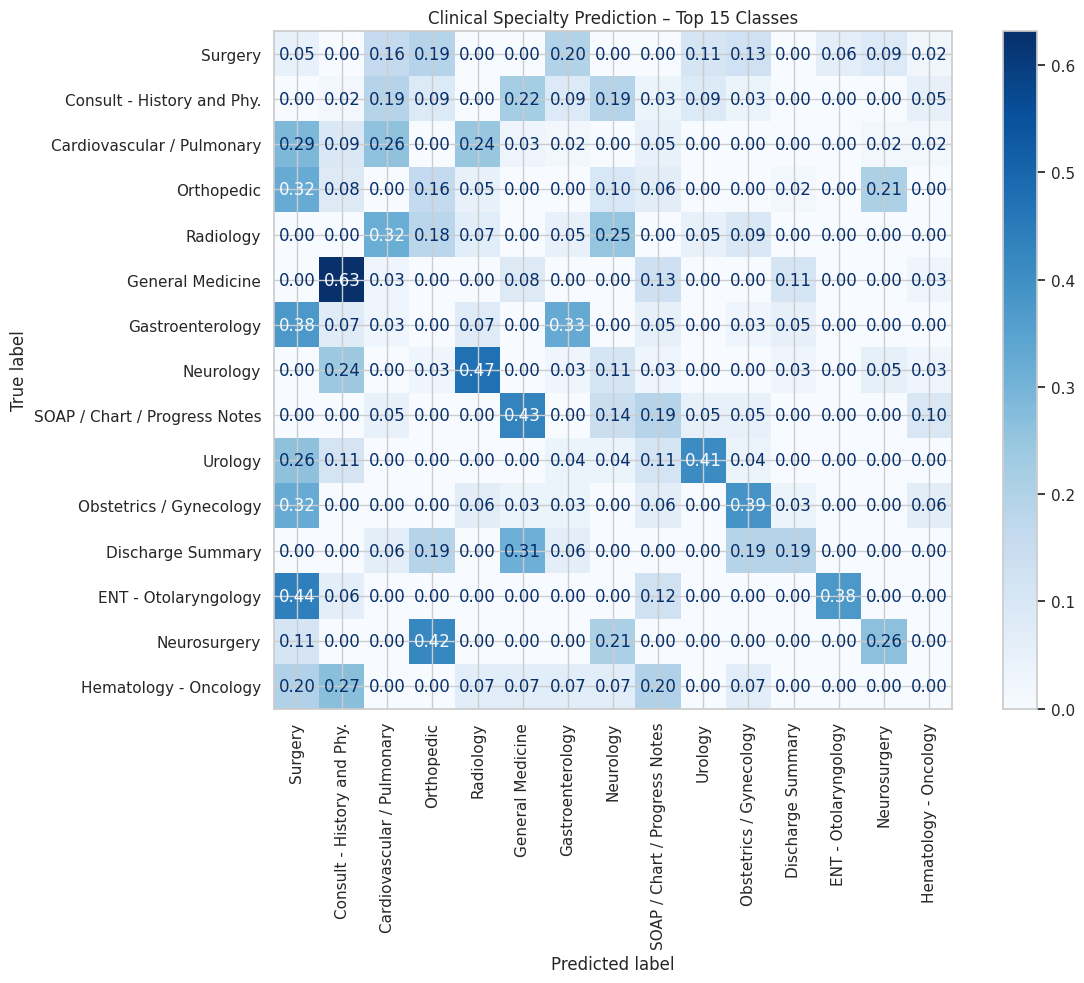

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Display only the 15 most frequent specialties
top_classes = model_df[specialty_col].value_counts().head(15).index

mask = y_test.isin(top_classes)
y_test_top = y_test[mask]
pred_top = pd.Series(pred, index=y_test.index)[mask]

ConfusionMatrixDisplay.from_predictions(
    y_test_top,
    pred_top,
    labels=top_classes,
    normalize="true",
    xticks_rotation=90,
    cmap="Blues",
    values_format=".2f"
)

plt.title("Clinical Specialty Prediction – Top 15 Classes")
plt.gcf().set_size_inches(13, 10)
plt.tight_layout()
plt.show()

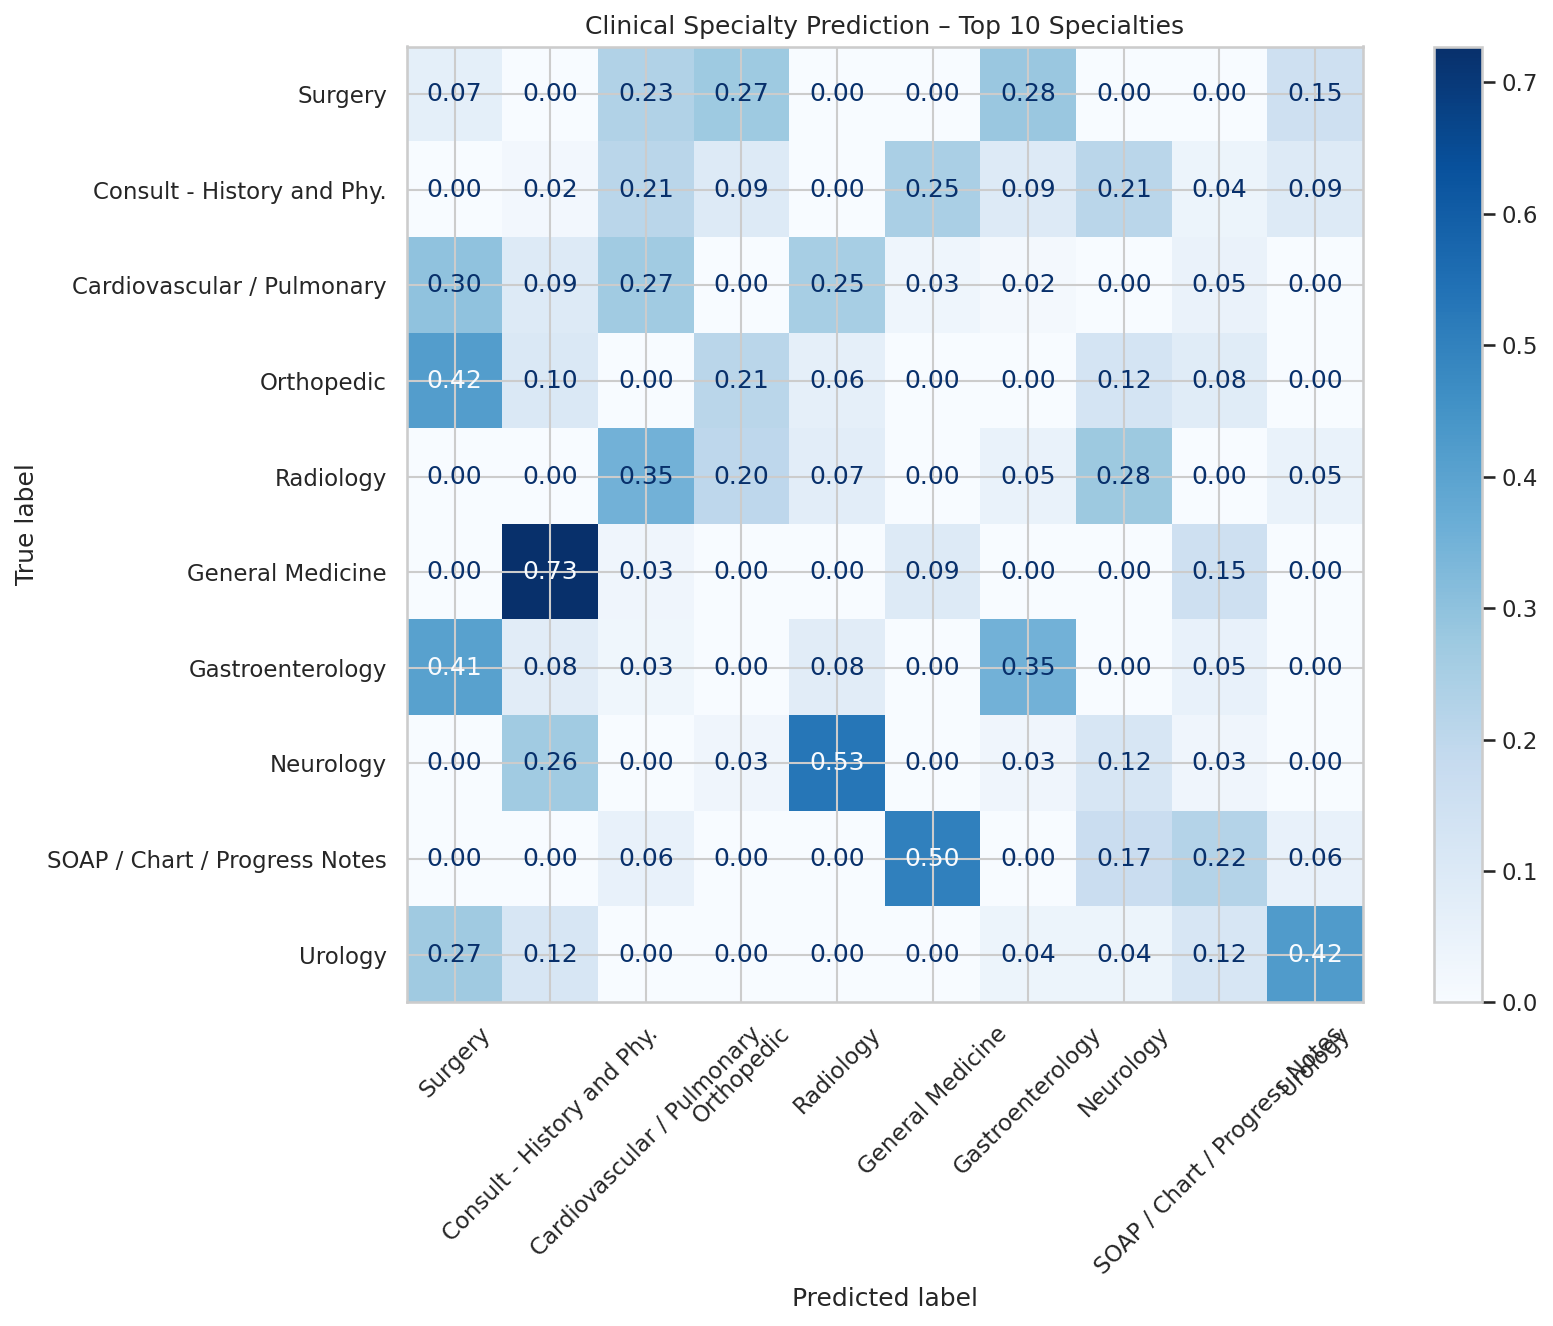

In [7]:
top_classes = model_df[specialty_col].value_counts().head(10).index

mask = y_test.isin(top_classes)
y_small = y_test[mask]
pred_small = pred[mask.to_numpy()]

fig, ax = plt.subplots(figsize=(12, 9), dpi=150)

ConfusionMatrixDisplay.from_predictions(
    y_small,
    pred_small,
    labels=top_classes,
    normalize="true",
    cmap="Blues",
    xticks_rotation=45,
    values_format=".2f",
    ax=ax
)

ax.set_title("Clinical Specialty Prediction – Top 10 Specialties")
plt.tight_layout()
plt.savefig("clinical_specialty_top10.png", dpi=300, bbox_inches="tight")
plt.show()

,reports,average_words,report_share_percent,review_priority_score
medical_specialty,,,,
Surgery,1088,484.15,21.91,100.0
Consult - History and Phy.,516,558.06,10.39,97.5
Cardiovascular / Pulmonary,371,433.60,7.47,95.0
Orthopedic,355,559.12,7.15,92.5
Radiology,273,274.61,5.50,90.0
General Medicine,259,467.10,5.22,87.5
Gastroenterology,224,358.69,4.51,85.0
Neurology,223,496.31,4.49,82.5
SOAP / Chart / Progress Notes,166,358.78,3.34,80.0


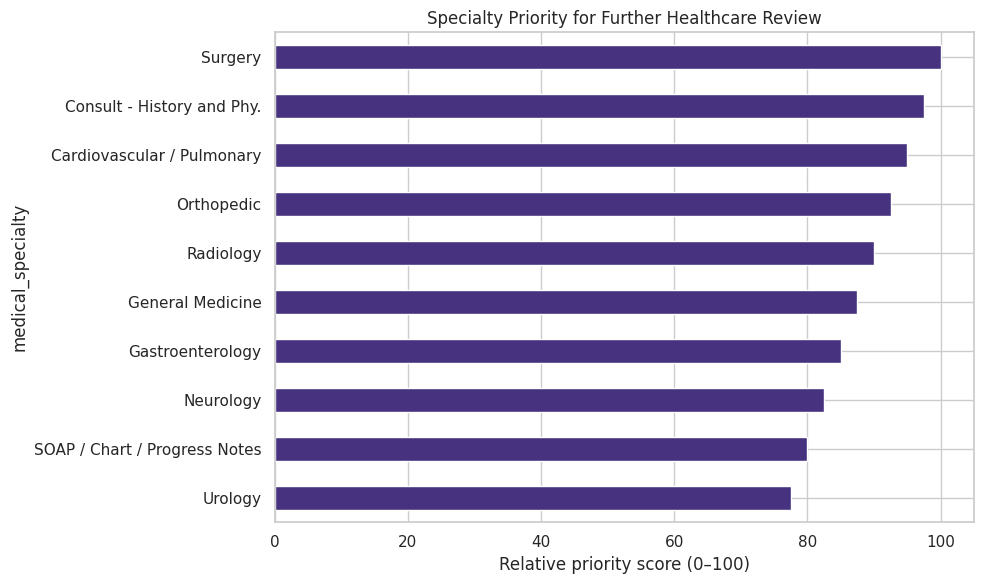

In [25]:
# T9: Rank specialties for further planning review

priority = df.groupby(specialty_col).agg(
    reports=(text_col, "size"),
    average_words=("word_count", "mean")
)

priority["report_share_percent"] = (
    priority["reports"] / len(df) * 100
)

# Transparent workload proxy, not a validated resource requirement
priority["review_priority_score"] = (
    priority["report_share_percent"].rank(pct=True) * 100
).round(1)

priority = priority.sort_values(
    "review_priority_score", ascending=False
)

display(priority.head(15).round(2))

plt.figure(figsize=(10, 6))
priority.head(10)["review_priority_score"].sort_values().plot(
    kind="barh"
)
plt.title("Specialty Priority for Further Healthcare Review")
plt.xlabel("Relative priority score (0–100)")
plt.tight_layout()
plt.show()

Number of specialties: 40

Top 10 specialties:
medical_specialty
Surgery                          1088
Consult - History and Phy.        516
Cardiovascular / Pulmonary        371
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  224
Neurology                         223
SOAP / Chart / Progress Notes     166
Urology                           156
Name: count, dtype: int64


,Missing values,Missing percentage,Unique values
unnamed: 0,0,0.00,4966
description,0,0.00,2336
medical_specialty,0,0.00,40
sample_name,0,0.00,2360
transcription,0,0.00,2357
keywords,1068,21.51,3816
clean_text,0,0.00,2355
word_count,0,0.00,921


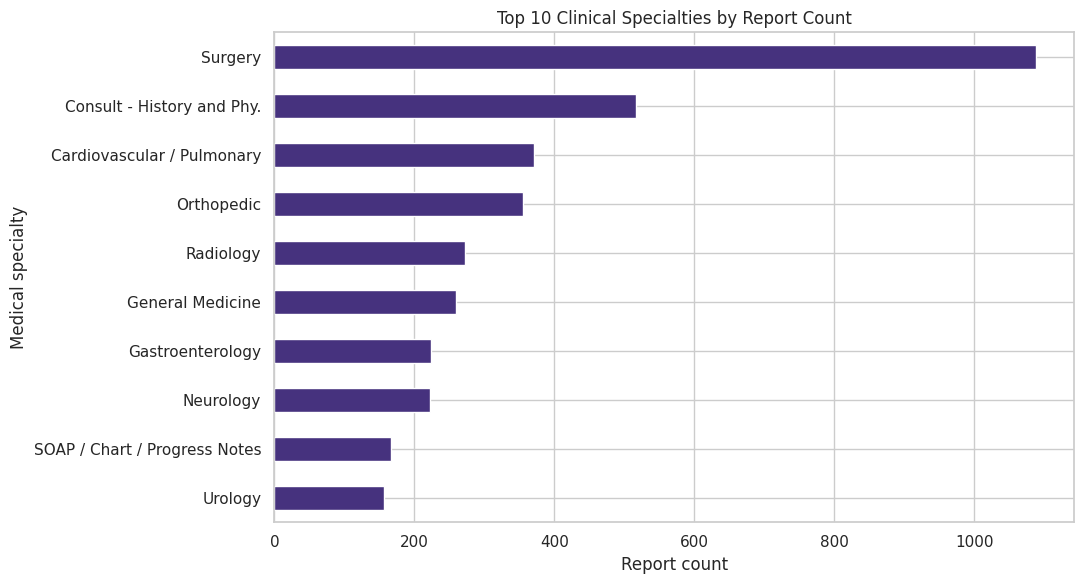

Top 5 specialties account for 52.42% of reports.


In [8]:
# Specialty distribution
specialty_counts = df[specialty_col].value_counts()

print("Number of specialties:", df[specialty_col].nunique())
print("\nTop 10 specialties:")
print(specialty_counts.head(10))

# Data quality report
quality = pd.DataFrame({
    "Missing values": df.isna().sum(),
    "Missing percentage": (df.isna().mean() * 100).round(2),
    "Unique values": df.nunique()
})

display(quality)

# Strategic planning chart
top10 = specialty_counts.head(10).sort_values()

plt.figure(figsize=(11, 6))
top10.plot(kind="barh")
plt.title("Top 10 Clinical Specialties by Report Count")
plt.xlabel("Report count")
plt.ylabel("Medical specialty")
plt.tight_layout()
plt.show()

# Share of reports in the five most frequent specialties
top5_share = specialty_counts.head(5).sum() / len(df) * 100
print(f"Top 5 specialties account for {top5_share:.2f}% of reports.")

,Clinical term,Mean TF-IDF
0,patient,0.066483
1,right,0.040554
2,left,0.039226
3,history,0.038615
4,normal,0.032877
5,procedure,0.032786
6,pain,0.027014
7,placed,0.026968
8,mg,0.024557
9,noted,0.018968


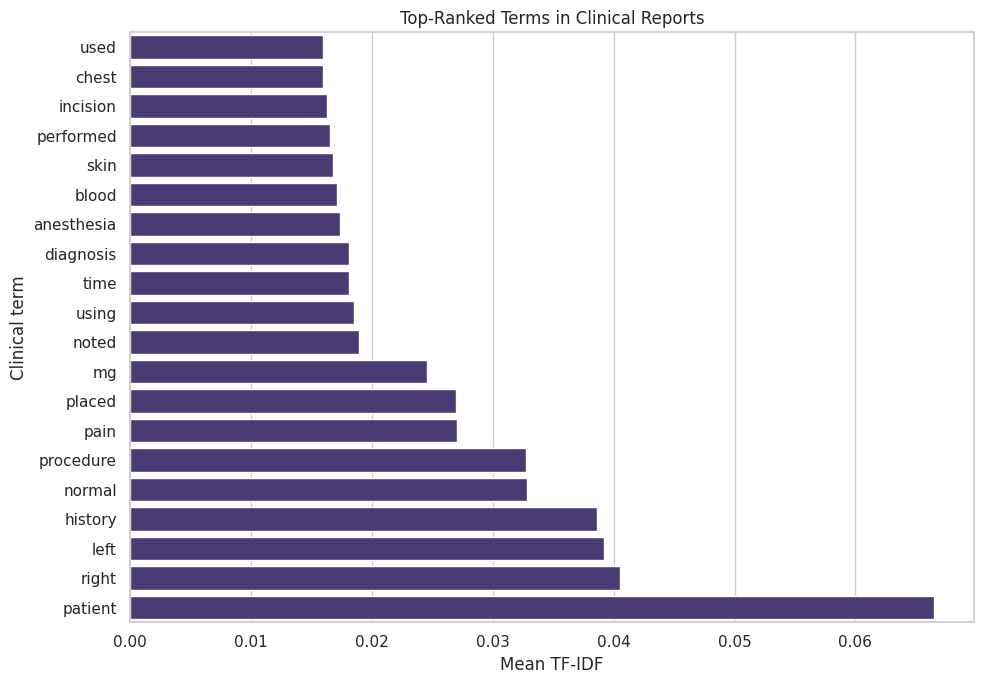

Enter a healthcare search query: left

Rank 1 | Similarity: 0.351
Specialty: Consult - History and Phy.
CC:, Stable expressive aphasia and decreased vision.,HX:, This 72y/o woman was diagnosed with a left sphenoid wing meningioma on 6/3/80. She was 59 years old at the time and presented with a 6 month history of increasing irritability and left occipital-nuchal headaches. One month prior to that presentation she developed leftward head turning, and 3 days prior to presentation had an episode of severe dysphasia. A HCT (done locally) revealed a homogenously enhancing lesion of the left sphenoid win

Rank 2 | Similarity: 0.351
Specialty: Neurology
CC:, Stable expressive aphasia and decreased vision.,HX:, This 72y/o woman was diagnosed with a left sphenoid wing meningioma on 6/3/80. She was 59 years old at the time and presented with a 6 month history of increasing irritability and left occipital-nuchal headaches. One month prior to that presentation she developed leftward head turning, a

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Rank clinical terms
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=3000,
    ngram_range=(1, 2),
    min_df=2
)

X_tfidf = vectorizer.fit_transform(df[text_col])
terms = np.array(vectorizer.get_feature_names_out())

mean_scores = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_indices = mean_scores.argsort()[-20:][::-1]

term_ranking = pd.DataFrame({
    "Clinical term": terms[top_indices],
    "Mean TF-IDF": mean_scores[top_indices]
})

display(term_ranking)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=term_ranking.sort_values("Mean TF-IDF"),
    x="Mean TF-IDF", y="Clinical term"
)
plt.title("Top-Ranked Terms in Clinical Reports")
plt.tight_layout()
plt.show()

# Search clinical reports
query = input("Enter a healthcare search query: ")

query_vector = vectorizer.transform([query])
similarities = cosine_similarity(query_vector, X_tfidf).ravel()

top_matches = similarities.argsort()[-5:][::-1]

for rank, idx in enumerate(top_matches, start=1):
    print(f"\nRank {rank} | Similarity: {similarities[idx]:.3f}")
    print("Specialty:", df.iloc[idx][specialty_col])
    print(df.iloc[idx][text_col][:500])

Silhouette score: 0.023

Reports per cluster:
cluster
0     167
1     596
2    1416
3    1259
4    1528
Name: count, dtype: int64


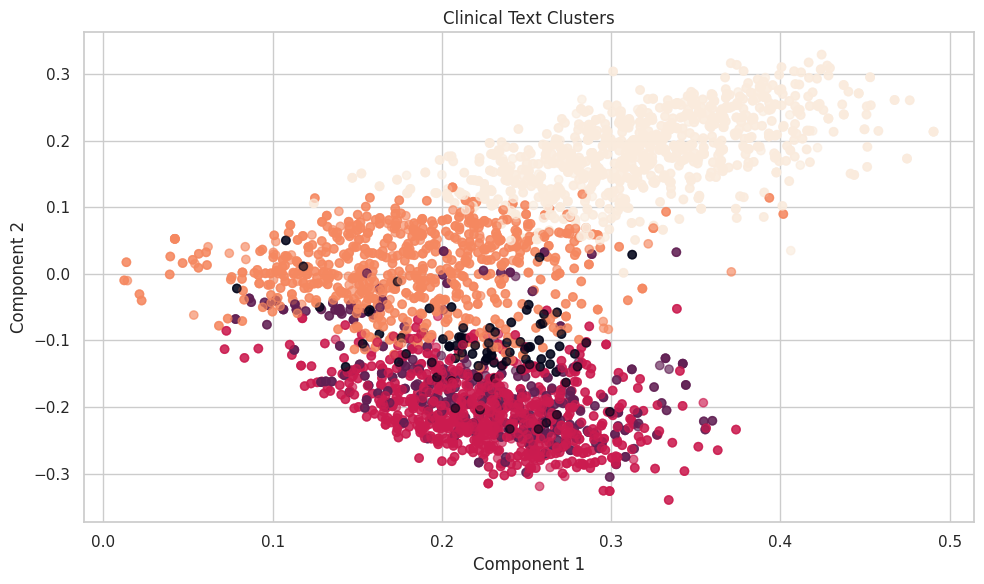


Cluster 0: artery, coronary, left, coronary artery, right, catheter, right coronary, stenosis, french, descending

Cluster 1: patient, placed, c5, medial, c6, left, procedure, lateral, tendon, right

Cluster 2: patient, procedure, placed, right, incision, anesthesia, left, using, diagnosis, removed

Cluster 3: normal, right, patient, left, exam, unremarkable, evidence, seen, procedure, pain

Cluster 4: history, patient, mg, pain, normal, past, denies, daily, does, negative


In [10]:
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

# Use the TF-IDF representation from T9
n_clusters = min(5, X_tfidf.shape[0] - 1)

if n_clusters >= 2:
    clustering = KMeans(
        n_clusters=n_clusters,
        random_state=42,
        n_init=10
    )

    cluster_labels = clustering.fit_predict(X_tfidf)
    df["cluster"] = cluster_labels

    print("Silhouette score:",
          round(silhouette_score(X_tfidf, cluster_labels), 3))

    print("\nReports per cluster:")
    print(df["cluster"].value_counts().sort_index())

    # Reduce to 2 dimensions for visualization
    svd = TruncatedSVD(n_components=2, random_state=42)
    coordinates = svd.fit_transform(X_tfidf)

    plt.figure(figsize=(10, 6))
    plt.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        c=cluster_labels,
        alpha=0.65
    )
    plt.title("Clinical Text Clusters")
    plt.xlabel("Component 1")
    plt.ylabel("Component 2")
    plt.tight_layout()
    plt.show()

    # Frequent terms in each cluster
    for cluster_id in range(n_clusters):
        cluster_docs = X_tfidf[cluster_labels == cluster_id]
        avg = np.asarray(cluster_docs.mean(axis=0)).ravel()
        top = avg.argsort()[-10:][::-1]
        print(f"\nCluster {cluster_id}:", ", ".join(terms[top]))

In [27]:
# T10: Interpret clusters and compare with known specialty labels

df["cluster"] = cluster_labels

print("Cluster sizes:")
display(df["cluster"].value_counts().sort_index().to_frame("Reports"))

print("\nMost common specialties within each cluster:")
cluster_summary = pd.crosstab(
    df["cluster"],
    df[specialty_col],
    normalize="index"
)

for cluster_id in cluster_summary.index:
    print(
        f"Cluster {cluster_id}:",
        cluster_summary.loc[cluster_id].nlargest(3).round(3).to_dict()
    )

# Compare predicted specialty with actual specialty
# using the classification model created in T7
from sklearn.metrics import f1_score, accuracy_score

# Fix: Use 'y_pred' instead of 'pred' to compare the multiclass classification results
print("Specialty classification accuracy:",
      round(accuracy_score(y_test, y_pred), 3))
print("Weighted F1:",
      round(f1_score(y_test, y_pred, average="weighted"), 3))

Cluster sizes:


,Reports
cluster,
0,167
1,596
2,1416
3,1259
4,1528



Most common specialties within each cluster:
Cluster 0: {'Cardiovascular / Pulmonary': 0.467, 'Surgery': 0.413, 'Radiology': 0.078}
Cluster 1: {'Orthopedic': 0.344, 'Surgery': 0.334, 'Neurosurgery': 0.084}
Cluster 2: {'Surgery': 0.483, 'Urology': 0.073, 'Cardiovascular / Pulmonary': 0.063}
Cluster 3: {'Radiology': 0.18, 'Neurology': 0.105, 'Surgery': 0.104}
Cluster 4: {'Consult - History and Phy.': 0.29, 'General Medicine': 0.153, 'SOAP / Chart / Progress Notes': 0.069}
Specialty classification accuracy: 0.099
Weighted F1: 0.094


,entity_type,entity,frequency
250,ORG,Vicryl,53
327,PERSON,Foley,41
315,PERSON,DIAGNOSIS,33
11,MEDICAL_TERM,infection,31
2,MEDICAL_TERM,biopsy,25
148,ORG,Metzenbaum,24
4,MEDICAL_TERM,cancer,23
298,PERSON,Bovie,23
161,ORG,Next,19
261,ORG,meatus,13


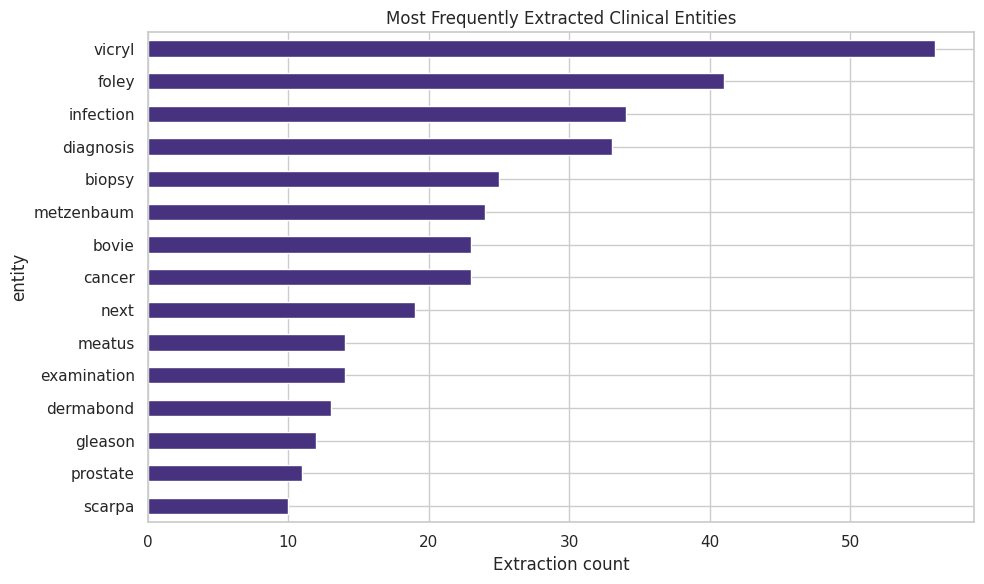

In [28]:
# T11: Summarize extracted medical entities

if not entity_df.empty:
    entity_summary = (
        entity_df.groupby(["entity_type", "entity"])
        .size()
        .reset_index(name="frequency")
        .sort_values("frequency", ascending=False)
    )

    display(entity_summary.head(30))

    # Visualize the most frequently extracted entities
    top_entities = (
        entity_df["entity"].str.lower()
        .value_counts()
        .head(15)
        .sort_values()
    )

    plt.figure(figsize=(10, 6))
    top_entities.plot(kind="barh")
    plt.title("Most Frequently Extracted Clinical Entities")
    plt.xlabel("Extraction count")
    plt.tight_layout()
    plt.show()
else:
    print("No entities were extracted. Check the dictionary and input text.")




In [11]:
%pip install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 30.9 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [12]:
import spacy
from collections import Counter

nlp = spacy.load("en_core_web_sm")

# Sample a few records to keep processing manageable
sample_df = df.head(100).copy()

# A simple rule-based medical term dictionary.
# Extend this dictionary for your selected clinical domain.
medical_terms = [
    "diabetes", "hypertension", "pneumonia", "asthma",
    "obesity", "chest pain", "headache", "fever",
    "infection", "cancer", "insulin", "aspirin",
    "metformin", "blood pressure", "heart disease",
    "magnetic resonance imaging", "MRI", "biopsy"
]

patterns = [
    {"label": "MEDICAL_TERM", "pattern": term}
    for term in medical_terms
]

from spacy.pipeline import EntityRuler

if "entity_ruler" not in nlp.pipe_names:
    ruler = nlp.add_pipe("entity_ruler", before="ner")
else:
    ruler = nlp.get_pipe("entity_ruler")

ruler.add_patterns(patterns)

entities = []

for row_id, text in zip(sample_df.index, sample_df[text_col]):
    doc = nlp(text[:10000])

    for ent in doc.ents:
        if ent.label_ in [
            "MEDICAL_TERM", "DISEASE", "ORG", "PERSON"
        ]:
            entities.append({
                "row_id": row_id,
                "entity": ent.text,
                "entity_type": ent.label_
            })

entity_df = pd.DataFrame(entities)

if not entity_df.empty:
    display(entity_df.head(30))
    display(entity_df["entity"].value_counts().head(20))
else:
    print("No matching entities found. Extend the terminology dictionary.")

,row_id,entity,entity_type
0,0,Claritin,PERSON
1,0,Allegra,ORG
2,0,asthma,MEDICAL_TERM
3,0,Ortho Tri-Cyclen,PERSON
4,0,Allegra,ORG
5,0,blood pressure,MEDICAL_TERM
6,0,Nasal,ORG
7,0,Allergic,ORG
8,0,Allegra,ORG
9,0,Samples of Nasonex,ORG


,count
entity,
Vicryl,56
Foley,41
DIAGNOSIS,33
infection,31
biopsy,25
Metzenbaum,24
Bovie,23
cancer,23
Next,19


In [29]:
# T12: Context-based word-sense disambiguation demonstration

def disambiguate_discharge(sentence):
    text = sentence.lower()

    meanings = {
        "hospital discharge": [
            "patient discharged", "discharged home",
            "discharge summary", "hospital discharge"
        ],
        "bodily discharge": [
            "vaginal discharge", "nasal discharge",
            "ear discharge", "fluid discharge"
        ],
        "wound discharge": [
            "wound discharge", "pus", "wound drainage"
        ]
    }

    scores = {
        meaning: sum(phrase in text for phrase in phrases)
        for meaning, phrases in meanings.items()
    }

    best_meaning = max(scores, key=scores.get)

    if scores[best_meaning] == 0:
        return "Ambiguous / insufficient context"

    return best_meaning


examples = [
    "The patient was discharged home in stable condition.",
    "The patient reports vaginal discharge.",
    "The wound has pus and wound drainage."
]

for sentence in examples:
    print("Text:", sentence)
    print("Interpretation:", disambiguate_discharge(sentence))
    print()

Text: The patient was discharged home in stable condition.
Interpretation: hospital discharge

Text: The patient reports vaginal discharge.
Interpretation: bodily discharge

Text: The wound has pus and wound drainage.
Interpretation: wound discharge



In [13]:
# Rank documents using a query
query = input("Enter a medical term or phrase: ")

query_vec = vectorizer.transform([query])
scores = cosine_similarity(query_vec, X_tfidf).ravel()

ranked_indices = np.argsort(scores)[::-1][:10]

results = pd.DataFrame({
    "Specialty": df.iloc[ranked_indices][specialty_col].values,
    "Similarity": scores[ranked_indices],
    "Clinical text": df.iloc[ranked_indices][text_col].str[:250].values
})

display(results)

# Investigate a term in different contexts
term = input("Enter a term to investigate: ").lower()

matches = df[
    df[text_col].str.contains(re.escape(term), case=False, na=False)
].head(10)

for _, row in matches.iterrows():
    print("\nSpecialty:", row[specialty_col])
    text = row[text_col]
    match = re.search(re.escape(term), text, flags=re.IGNORECASE)

    if match:
        start = max(0, match.start() - 100)
        end = min(len(text), match.end() + 150)
        print(text[start:end])

Enter a medical term or phrase: end


,Specialty,Similarity,Clinical text
0,Nephrology,0.255637,"PREOPERATIVE DIAGNOSIS,End-stage renal disease..."
1,Surgery,0.255637,"PREOPERATIVE DIAGNOSIS,End-stage renal disease..."
2,Nephrology,0.182785,"PREOPERATIVE DIAGNOSES,1. End-stage renal dis..."
3,Surgery,0.182785,"PREOPERATIVE DIAGNOSES,1. End-stage renal dis..."
4,Nephrology,0.177793,"PREOPERATIVE DIAGNOSES,1. End-stage renal dis..."
5,Surgery,0.177793,"PREOPERATIVE DIAGNOSES,1. End-stage renal dis..."
6,Surgery,0.167114,"PREOPERATIVE DIAGNOSES,1. End-stage renal dis..."
7,Nephrology,0.167114,"PREOPERATIVE DIAGNOSES,1. End-stage renal dis..."
8,Radiology,0.160963,"FINDINGS:,Axial scans were performed from L1 t..."
9,Orthopedic,0.160963,"FINDINGS:,Axial scans were performed from L1 t..."


Enter a term to investigate: surgery

Specialty: Bariatrics
 swelling.  He has gastroesophageal reflux disease.,PAST SURGICAL HISTORY:, Includes reconstructive surgery on his right hand 13 years ago.  ,SOCIAL HISTORY:, He is currently single.  He has about ten drinks a year.  He had smoked significantly up until sev

Specialty: Bariatrics
n, leg and foot swelling.  He has hemorrhoids.,PAST SURGICAL HISTORY: , Includes orthopedic or knee surgery.,SOCIAL HISTORY: , He is currently single.  He drinks alcohol ten to twelve drinks a week, but does not drink five days a week and then will binge dr

Specialty: Bariatrics
any years.  She has tried many different diets, but is unsuccessful.  She has been to our Bariatric Surgery Seminar, received some handouts, and signed the consent.  The risks and benefits of the procedure have been explained to the patient.,PROCEDURE IN DE

Specialty: Bariatrics
patient has read through our comprehensive handout and understands the risks and benefits of bypa

Explained variance by PC1 and PC2: [0.929 0.051]
Total explained variance: 0.981


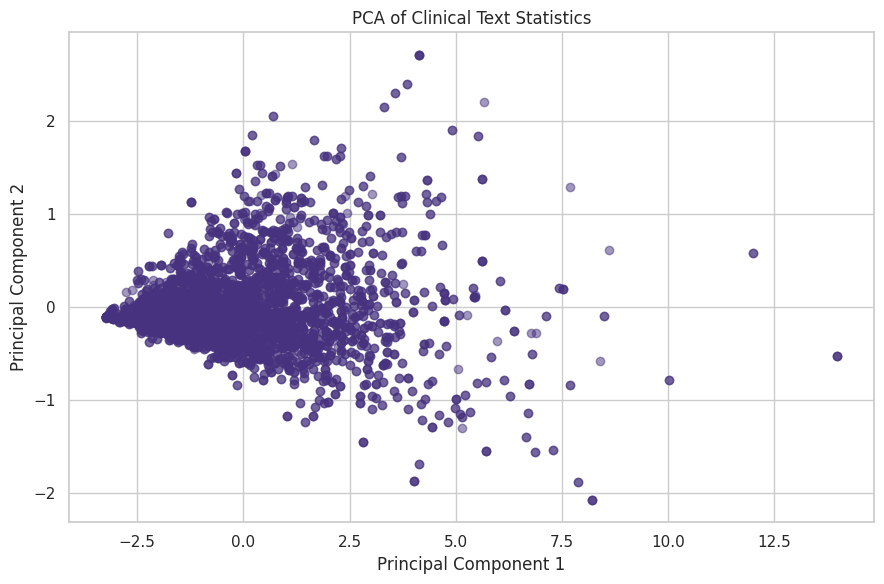

In [30]:
# T13: PCA on numerical clinical-text features

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

numeric_features = pd.DataFrame(index=df.index)

numeric_features["word_count"] = df[text_col].str.split().str.len()
numeric_features["character_count"] = df[text_col].str.len()
numeric_features["sentence_count"] = df[text_col].str.count(r"[.!?]+")
numeric_features["unique_word_count"] = df[text_col].apply(
    lambda x: len(set(re.findall(r"\b\w+\b", x.lower())))
)

scaled = StandardScaler().fit_transform(
    numeric_features.fillna(0)
)

pca = PCA(n_components=2)
components = pca.fit_transform(scaled)

print("Explained variance by PC1 and PC2:",
      pca.explained_variance_ratio_.round(3))
print("Total explained variance:",
      round(pca.explained_variance_ratio_.sum(), 3))

plt.figure(figsize=(9, 6))
plt.scatter(components[:, 0], components[:, 1], alpha=0.5)
plt.title("PCA of Clinical Text Statistics")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

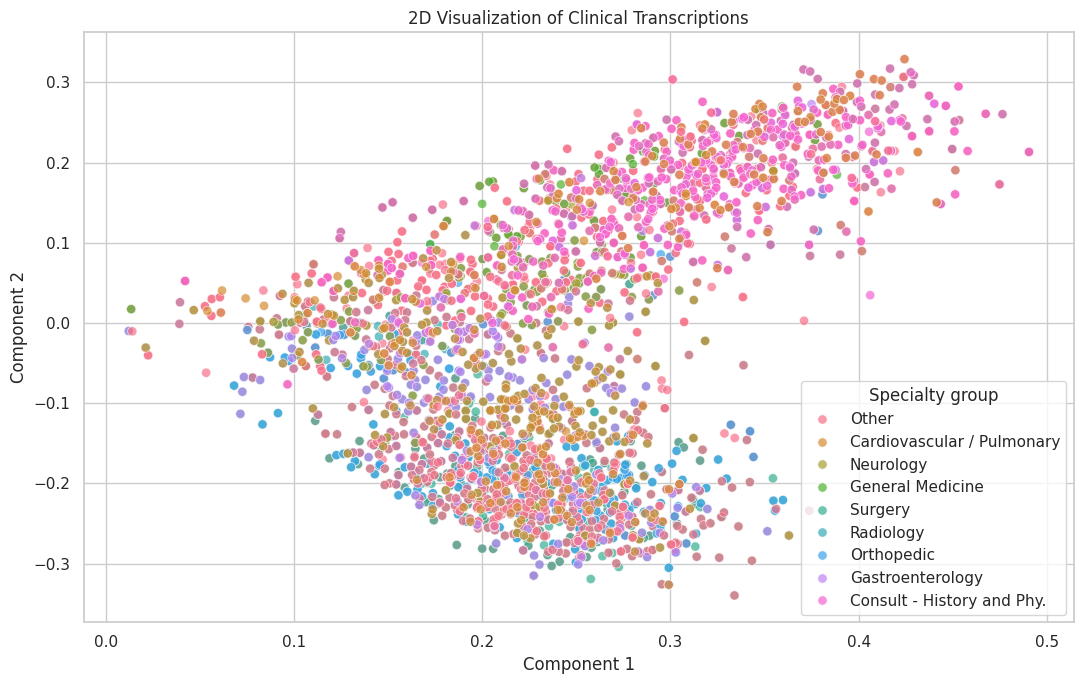

Explained variance ratio of the two components: 0.0369


In [14]:
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import StandardScaler

# SVD is suitable for sparse TF-IDF text matrices.
svd = TruncatedSVD(n_components=2, random_state=42)
reduced = svd.fit_transform(X_tfidf)

plot_df = pd.DataFrame({
    "Component 1": reduced[:, 0],
    "Component 2": reduced[:, 1],
    "Specialty": df[specialty_col].values
})

# Keep the largest specialties legible
top_specialties = df[specialty_col].value_counts().head(8).index
plot_df["Specialty group"] = plot_df["Specialty"].where(
    plot_df["Specialty"].isin(top_specialties),
    "Other"
)

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=plot_df,
    x="Component 1",
    y="Component 2",
    hue="Specialty group",
    alpha=0.7,
    s=45
)
plt.title("2D Visualization of Clinical Transcriptions")
plt.tight_layout()
plt.show()

print("Explained variance ratio of the two components:",
      round(svd.explained_variance_ratio_.sum(), 4))

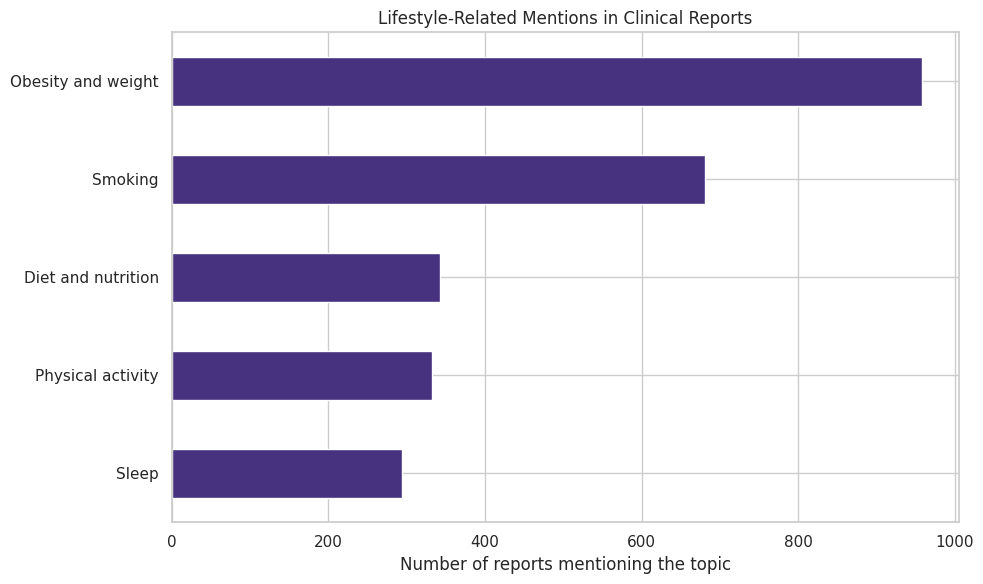

,Report count
Sleep,294
Physical activity,332
Diet and nutrition,342
Smoking,681
Obesity and weight,958



Lifestyle-topic mentions by specialty:


,Diet and nutrition,Physical activity,Obesity and weight,Smoking,Sleep
medical_specialty,,,,,
Consult - History and Phy.,66,76,236,193,74
General Medicine,32,19,107,72,27
SOAP / Chart / Progress Notes,30,21,70,18,11
Surgery,21,9,52,19,8
Cardiovascular / Pulmonary,15,34,51,40,13
Neurology,7,37,49,68,35
Orthopedic,8,27,43,35,11
Obstetrics / Gynecology,11,2,41,14,4
Pediatrics - Neonatal,18,3,39,15,2


In [15]:
# Identify reports mentioning lifestyle-related topics
behavior_patterns = {
    "Diet and nutrition": r"\bdiet\b|\bnutrition\b|\bcalorie",
    "Physical activity": r"\bexercise\b|\bphysical activity\b|\bwalking\b",
    "Obesity and weight": r"\bobesity\b|\bobese\b|\bweight\b|\bBMI\b",
    "Smoking": r"\bsmoking\b|\btobacco\b|\bcigarette",
    "Sleep": r"\bsleep\b|\binsomnia\b|\bsleep apnea\b"
}

for category, pattern in behavior_patterns.items():
    df[category] = df[text_col].str.contains(
        pattern, case=False, regex=True, na=False
    )

behavior_counts = df[list(behavior_patterns)].sum().sort_values()

plt.figure(figsize=(10, 6))
behavior_counts.plot(kind="barh")
plt.title("Lifestyle-Related Mentions in Clinical Reports")
plt.xlabel("Number of reports mentioning the topic")
plt.tight_layout()
plt.show()

display(behavior_counts.to_frame("Report count"))

# Compare mentions across specialties
print("\nLifestyle-topic mentions by specialty:")
display(
    df.groupby(specialty_col)[list(behavior_patterns)]
      .sum()
      .sort_values("Obesity and weight", ascending=False)
      .head(10)
)

                           precision    recall  f1-score   support

No weight-related mention       0.98      0.90      0.94       802
   Weight-related mention       0.68      0.92      0.78       192

                 accuracy                           0.90       994
                macro avg       0.83      0.91      0.86       994
             weighted avg       0.92      0.90      0.91       994



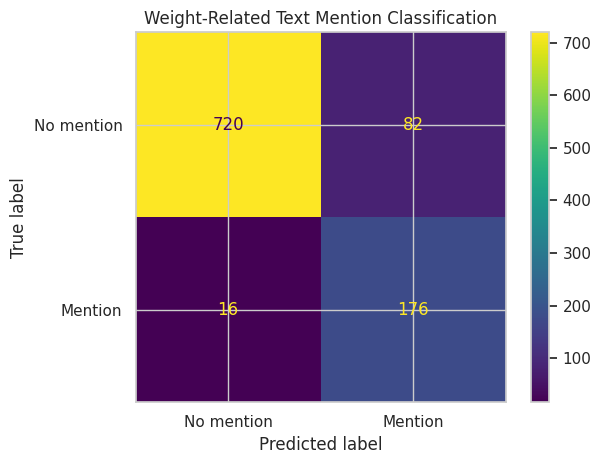

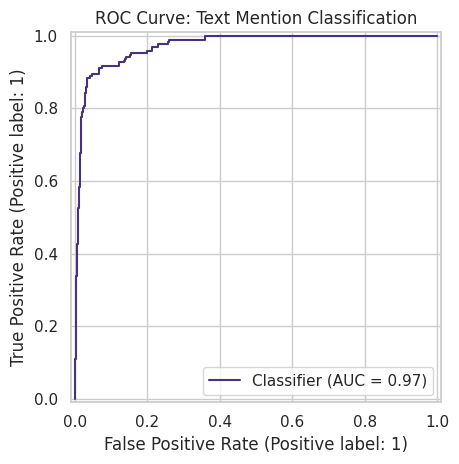

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay

# Define a text-based target
target = df["Obesity and weight"].astype(int)

if target.nunique() < 2 or target.value_counts().min() < 2:
    print("Insufficient examples in one class for a reliable model.")
else:
    X_train, X_test, y_train, y_test = train_test_split(
        df[text_col],
        target,
        test_size=0.2,
        random_state=42,
        stratify=target
    )

    weight_text_model = Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english",
            max_features=3000,
            ngram_range=(1, 2)
        )),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000
        ))
    ])

    weight_text_model.fit(X_train, y_train)
    pred = weight_text_model.predict(X_test)
    prob = weight_text_model.predict_proba(X_test)[:, 1]

    print(classification_report(
        y_test, pred, target_names=[
            "No weight-related mention",
            "Weight-related mention"
        ],
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        display_labels=["No mention", "Mention"]
    )
    plt.title("Weight-Related Text Mention Classification")
    plt.tight_layout()
    plt.show()

    if y_test.nunique() == 2:
        RocCurveDisplay.from_predictions(y_test, prob)
        plt.title("ROC Curve: Text Mention Classification")
        plt.tight_layout()
        plt.show()

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [36]:

# T15: Feature Importance - Corrected

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

print("Model pipeline steps:", model.named_steps.keys())

# Find the preprocessing step
preprocessor_name = next(
    (name for name in model.named_steps
     if name in ["preprocessor", "preprocess", "prep"]),
    None
)

if preprocessor_name is None:
    print(
        "No preprocessing step found. "
        "Check the pipeline steps printed above."
    )
else:
    preprocessor = model.named_steps[preprocessor_name]

    # Get transformed feature names
    feature_names = preprocessor.get_feature_names_out()

    # Find the classifier step
    classifier = model.steps[-1][1]

    if hasattr(classifier, "feature_importances_"):
        importance = classifier.feature_importances_

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importance
        }).sort_values("Importance", ascending=False)

        print("\nTop 15 important features:")
        display(importance_df.head(15))

        top_features = importance_df.head(15).sort_values("Importance")

        plt.figure(figsize=(10, 6))
        plt.barh(
            top_features["Feature"],
            top_features["Importance"]
        )
        plt.xlabel("Feature Importance")
        plt.title("Top 15 Features for Obesity Category Prediction")
        plt.tight_layout()
        plt.show()

    else:
        print(
            "The final model does not support feature_importances_. "
            "If you trained LinearSVC, use model coefficients instead."
        )


Model pipeline steps: dict_keys(['tfidf', 'classifier'])
No preprocessing step found. Check the pipeline steps printed above.
